<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS13/Praktikum3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 884ms/step - loss: 2.8694
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 2.8496
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 2.8300
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - loss: 2.8104
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - loss: 2.7910
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - loss: 2.7716
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 2.7524
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - loss: 2.7332
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - loss: 2.7142
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - loss: 2.6952
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 2.6764
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 2.6577
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 2.6391
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2.6205
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 2.6021
Epoch 16/100
1/1 ━━━━━━━

Tugas 4

- Ubah learning rate.

- Bandingkan hasil loss.

In [2]:
import numpy as np

# 1. Dummy Dataset
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# 2. Normalisasi Data
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# 3. Split Data (menggunakan random_state agar perbandingan adil)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42
)

# 4. Fungsi untuk Melatih Model berdasarkan Learning Rate
def train_regression_model(learning_rate):
    tf.keras.utils.set_random_seed(42)  # Menjaga konsistensi inisialisasi bobot

    # Arsitektur Model Regresi
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1) # Linear activation untuk regresi
    ])

    # Mengatur Learning Rate pada Adam Optimizer
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    # Kompilasi Model dengan MSE Loss
    model.compile(optimizer=optimizer, loss='mse')

    # Latih Model
    history = model.fit(X_train, y_train, epochs=100, verbose=0)

    # Evaluasi Loss Akhir di Data Test
    test_loss = model.evaluate(X_test, y_test, verbose=0)
    pred_scaled = model.predict(X_test, verbose=0)

    # Denormalisasi Prediksi Kembali ke Skala Asli (Rupiah/Juta)
    pred_original = scaler_y.inverse_transform(pred_scaled)

    return test_loss, pred_original

# --- RUN EKSPERIMEN TUGAS 4 ---
lr_values = [0.1, 0.001, 0.0001]
results = {}

print("=== HASIL EKSPERIMEN TUGAS 4 ===")
for lr in lr_values:
    loss, pred = train_regression_model(lr)
    results[lr] = (loss, pred)
    print(f"Learning Rate: {lr:<6} | Test Loss (MSE): {loss:.6f}")

# Menampilkan Nilai Asli vs Hasil Prediksi
y_test_original = scaler_y.inverse_transform(y_test)
print(f"\nTarget Asli (Data Uji): {y_test_original.ravel()}")
for lr, (loss, pred) in results.items():
    print(f"Prediksi (LR={lr:<6}): {np.round(pred.ravel(), 2)}")

=== HASIL EKSPERIMEN TUGAS 4 ===
Learning Rate: 0.1    | Test Loss (MSE): 0.027423
Learning Rate: 0.001  | Test Loss (MSE): 0.477486
Learning Rate: 0.0001 | Test Loss (MSE): 0.905758

Target Asli (Data Uji): [600.]
Prediksi (LR=0.1   ): [576.58]
Prediksi (LR=0.001 ): [697.72]
Prediksi (LR=0.0001): [734.59]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


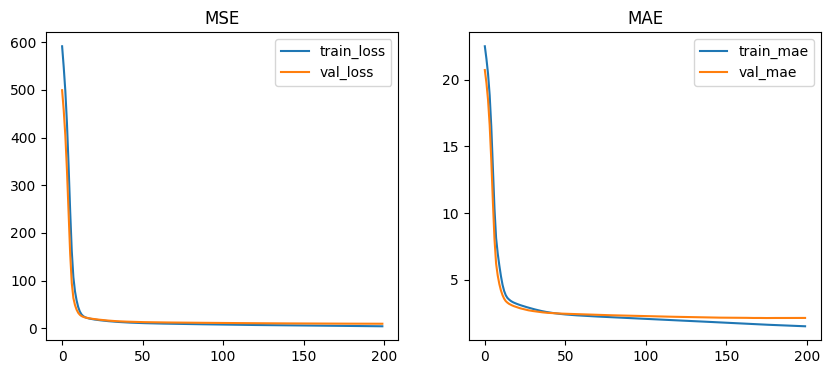

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
RMSE: 3.078148081736508


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# 1. Load Dataset Boston via OpenML (Pengganti load_boston yang paling stabil)
boston = fetch_openml(name='boston', version=1, as_frame=False, parser='auto')
X = boston.data
y = boston.target.astype(np.float32)

# 2. Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

# Evaluasi Prediksi
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))